# Baseline Comparison: Logistic Regression on Word2Vec

This notebook trains the same Logistic Regression classifier as the baseline, but on averaged Word2Vec embeddings instead of TF-IDF features. It uses the identical train/test split and evaluation metric (Fake-class recall), so any difference in performance comes from the text representation alone. The TF-IDF model remains the official baseline; this notebook tests whether a richer representation justifies losing word-level interpretability.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from gensim.models import Word2Vec
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)

from preprocessing import preprocess_text, get_train_test_split, RANDOM_STATE

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing

Same NLP pipeline as the TF-IDF baseline (`preprocess_text` from `preprocessing.py`). Word2Vec expects a list of tokens per article, so the processed text is split into words.

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df["tokens"] = df["processed_text"].str.split()

df[["processed_text", "tokens"]].head()

,processed_text,tokens
0,foreign democrat final tax development store a...,"[foreign, democrat, final, tax, development, s..."
1,offer resource great point probably guess west...,"[offer, resource, great, point, probably, gues..."
2,church carry identify forward present success ...,"[church, carry, identify, forward, present, su..."
3,unit phone item yard republican safe police id...,"[unit, phone, item, yard, republican, safe, po..."
4,billion believe employee summer wonder fact di...,"[billion, believe, employee, summer, wonder, f..."


## 4. Train/Test Split

The split is done **before** training Word2Vec so the test articles never influence the word vectors. Passing row indices through `get_train_test_split` reuses the exact same `test_size`, `stratify`, and `random_state`, so the train/test rows are identical to the TF-IDF baseline.

In [4]:
y = df["label_encoded"]

idx_train, idx_test, y_train, y_test = get_train_test_split(np.arange(len(df)), y)

train_tokens = df["tokens"].iloc[idx_train]
test_tokens = df["tokens"].iloc[idx_test]

print("Train size:", len(idx_train))
print("Test size:", len(idx_test))
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train size: 16000
Test size: 4000

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 5. Train Word2Vec (Training Articles Only)

workers=1 and a fixed seed remove the main sources of randomness (multi-threaded training is non-deterministic). Full reproducibility across kernel restarts also requires the PYTHONHASHSEED environment variable to be fixed before Jupyter starts, because Gensim uses Python’s string hashing to initialise word vectors. Without it, results may vary slightly between restarts.

In [5]:
VECTOR_SIZE = 100

w2v = Word2Vec(
    sentences=train_tokens.tolist(),
    vector_size=VECTOR_SIZE,
    window=5,
    min_count=5,
    workers=1,
    epochs=10,
    seed=RANDOM_STATE
)

print("Vocabulary size:", len(w2v.wv))

Vocabulary size: 868


## 6. Build Article Vectors

Each article is represented as the average of its word vectors. Words not in the Word2Vec vocabulary are skipped; an article with no known words becomes a zero vector.

In [6]:
def document_vector(tokens, model):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

X_train = np.vstack(train_tokens.apply(lambda t: document_vector(t, w2v)))
X_test = np.vstack(test_tokens.apply(lambda t: document_vector(t, w2v)))

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (16000, 100)
X_test shape: (4000, 100)


## 7. Train Logistic Regression

In [7]:
log_reg_w2v = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
log_reg_w2v.fit(X_train, y_train)

y_pred = log_reg_w2v.predict(X_test)

## 8. Evaluation

Primary metric: recall on the **Fake** class (`label_encoded = 1`).

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
print(f"Recall on Fake class (primary metric): {recall_fake:.4f}")
print(f"Accuracy: {accuracy:.4f}")

              precision    recall  f1-score   support

        real       0.52      0.48      0.50      1989
        fake       0.52      0.56      0.54      2011

    accuracy                           0.52      4000
   macro avg       0.52      0.52      0.52      4000
weighted avg       0.52      0.52      0.52      4000

Recall on Fake class (primary metric): 0.5599
Accuracy: 0.5222


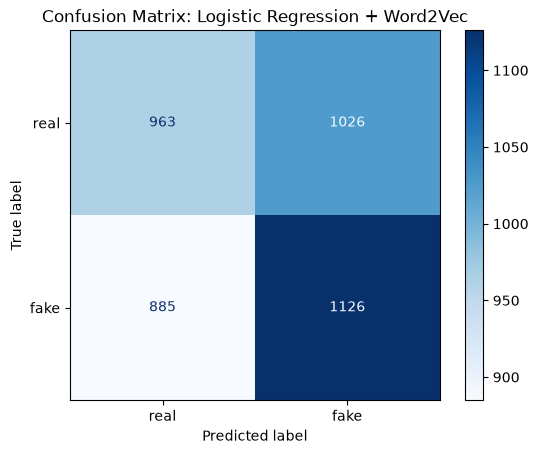

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["real", "fake"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix: Logistic Regression + Word2Vec")
plt.show()

- True Positive, correctly caught fake news article: 1,126
- False Negative, fake news article predicted as real: 885
- False Positive, real article predicted as fake: 1,026
- True Negative, correctly identified real article: 963

Word2Vec catches 56.0% of fake articles (recall = 0.5599), with precision of about 0.52 and accuracy of 52.2%. That’s a small step up from the TF-IDF baseline (recall 0.516, accuracy 0.498), but still close to the 50.3% you would get by always predicting “fake.”

In practice, about 44% of fake articles still slip through and nearly half of all flags are false alarms, so the model is not usable for trust-and-safety review.

Because the TF-IDF baseline showed no learnable signal at all (permutation test p = 0.158), a 2-point accuracy gain on a single test split needs to be checked before we treat it as real. See Section 8.1.

### 8.1 Sanity Check: Is the Gain Real?

The TF-IDF baseline showed no learnable signal (p = 0.158). To check whether Word2Vec's small gain is real or just a lucky split, we run the same test: a dummy baseline, plus the same model on shuffled labels.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import permutation_test_score, StratifiedKFold

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dummy (always 'fake') accuracy: {dummy.score(X_test, y_test):.4f}")

score, perm_scores, p_value = permutation_test_score(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    X_train, y_train, scoring="accuracy",
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_permutations=100, random_state=RANDOM_STATE, n_jobs=-1
)
print(f"CV accuracy (real labels):     {score:.4f}")
print(f"CV accuracy (shuffled labels): {perm_scores.mean():.4f}")
print(f"p-value: {p_value:.3f}")

Dummy (always 'fake') accuracy: 0.5028
CV accuracy (real labels):     0.5042
CV accuracy (shuffled labels): 0.5000
p-value: 0.228


## 9. Interpretability Check: What Do the Features Mean?

Unlike TF-IDF, each Word2Vec feature is an abstract dimension (dim_0 … dim_99), not a word. The model still has coefficients, but they can’t be read as “this word pushes toward fake.” Each dimension is a blend of many words at once, and no dimension has a human meaning.

The dimensions were also not standardised, so their scales differ. A larger coefficient does not necessarily mean a more important dimension. The table below shows which dimensions the model uses, not why.

In [11]:
coef_w2v = pd.DataFrame({
    "dimension": [f"dim_{i}" for i in range(VECTOR_SIZE)],
    "coefficient": log_reg_w2v.coef_[0]
})
coef_w2v["abs_coef"] = coef_w2v["coefficient"].abs()

display(coef_w2v.sort_values("abs_coef", ascending=False).head(10))

,dimension,coefficient,abs_coef
4,dim_4,-1.230885,1.230885
36,dim_36,1.169314,1.169314
83,dim_83,1.150989,1.150989
99,dim_99,1.023621,1.023621
51,dim_51,1.010668,1.010668
8,dim_8,0.964072,0.964072
97,dim_97,0.939629,0.939629
79,dim_79,-0.817638,0.817638
26,dim_26,-0.778948,0.778948
34,dim_34,-0.746375,0.746375


In [12]:
# Sanity check: does Word2Vec group related words together?
for word in ["economy", "government", "health"]:
    if word in w2v.wv:
        print(word, "->", [w for w, _ in w2v.wv.most_similar(word, topn=5)])

economy -> ['prepare', 'option', 'level', 'activity', 'least']
government -> ['send', 'political', 'concern', 'study', 'learn']
health -> ['building', 'example', 'choice', 'accept', 'order']


The nearest neighbours make little sense: economy sits closest to prepare and option, and health sits closest to building and example. (government → political is the one sensible pair, and it’s most likely a coincidence.) In real news, Word2Vec would place economy near words like market or inflation.

This is exactly what we’d expect if the text is randomly generated. Word2Vec learns meaning from which words tend to appear together, and in random word sequences, any word is equally likely to appear next to any other. The vocabulary is also tiny: 868 words across 20,000 articles, almost the same as TF-IDF’s 867 features. That points to a small, fixed word list used to generate the text, rather than real writing.

So the embeddings carry no real meaning, which explains why Word2Vec’s small accuracy gain turned out to be noise (Section 8.1).

## 10. Comparison: TF-IDF vs Word2Vec

In [13]:
# TF-IDF values copied from logistic_regression_TF-IDF.ipynb (same split, same classifier)
comparison = pd.DataFrame({
    "Representation": ["TF-IDF", "Word2Vec (averaged, 100-dim)"],
    "Fake-class Recall": [0.5162, round(recall_fake, 4)],
    "Accuracy": [0.4980, round(accuracy, 4)],
    "Missed fakes (FN)": [973, int(cm[1, 0])],
    "False alarms (FP)": [1035, int(cm[0, 1])],
    "Feature meaning": ["Each feature = a word", "Each feature = abstract dimension"],
    "Directly interpretable": ["Yes (coefficients → odds ratios)", "No"]
})
comparison

,Representation,Fake-class Recall,Accuracy,Missed fakes (FN),False alarms (FP),Feature meaning,Directly interpretable
0,TF-IDF,0.5162,0.4980,973,1035,Each feature = a word,Yes (coefficients → odds ratios)
1,"Word2Vec (averaged, 100-dim)",0.5599,0.5222,885,1026,Each feature = abstract dimension,No


## 11. Summary

This notebook tested whether a different text representation helps, keeping everything else the same as the TF-IDF baseline: same split, same classifier, same metric. On the test split, Word2Vec raised Fake-class recall from 0.516 to 0.560 and accuracy from 0.498 to 0.522. The sanity check (p = 0.228) shows this gain is not real: cross-validated accuracy is only 50.4%, no better than shuffled labels or always predicting "fake." Changing the representation does not help because the text itself carries no fake/real signal. Since Word2Vec also gives up word-level interpretability, TF-IDF remains the official baseline.